In [ ]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
GPU available: True
GPU: NVIDIA A100-SXM4-40GB


In [ ]:

%cd /content
!git clone https://github.com/piddnad/DDColor.git
%cd /content/DDColor

!pip -q install timm huggingface_hub einops opencv-python-headless


/content
Cloning into 'DDColor'...
remote: Enumerating objects: 285, done.
remote: Counting objects: 100% (113/113), done.
remote: Compressing objects: 100% (72/72), done.
remote: Total 285 (delta 71), reused 41 (delta 41), pack-reused 172 (from 1)
Receiving objects: 100% (285/285), 15.21 MiB | 19.23 MiB/s, done.
Resolving deltas: 100% (106/106), done.
/content/DDColor


In [ ]:

from huggingface_hub import hf_hub_download

model_path = hf_hub_download(
    repo_id="piddnad/ddcolor_modelscope",
    filename="pytorch_model.bin"
)

print("Model downloaded:", model_path)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  912MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Model downloaded: /root/.cache/huggingface/hub/models--piddnad--ddcolor_modelscope/snapshots/060f67494e31883a4b13cb27f889f3154847ada4/pytorch_model.bin


In [ ]:

%cd /content/DDColor

import os

print("Repository files:")
for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
    level = root.count(os.sep)
    if level > 2:
        continue
    for f in files:
        if f.endswith((".py", ".yaml", ".yml", ".md")):
            print(os.path.join(root, f))


/content/DDColor
Repository files:
./cog.yaml
./MODEL_ZOO.md
./README.md
./setup.py
./ddcolor/model.py
./ddcolor/__init__.py
./ddcolor/pipeline.py
./basicsr/__init__.py
./basicsr/train.py
./basicsr/models/base_model.py
./basicsr/models/lr_scheduler.py
./basicsr/models/__init__.py
./basicsr/models/color_model.py
./basicsr/utils/img_process_util.py
./basicsr/utils/flow_util.py
./basicsr/utils/file_client.py
./basicsr/utils/dist_util.py
./basicsr/utils/logger.py
./basicsr/utils/matlab_functions.py
./basicsr/utils/registry.py
./basicsr/utils/options.py
./basicsr/utils/__init__.py
./basicsr/utils/download_util.py
./basicsr/utils/diffjpeg.py
./basicsr/utils/misc.py
./basicsr/utils/img_util.py
./basicsr/utils/lmdb_util.py
./basicsr/utils/color_enhance.py
./basicsr/utils/face_util.py
./basicsr/losses/__init__.py
./basicsr/losses/losses.py
./basicsr/losses/loss_util.py
./basicsr/archs/ddcolor_arch.py
./basicsr/archs/__init__.py
./basicsr/archs/discriminator_arch.py
./basicsr/archs/vgg_arch.py
.

In [ ]:

from pathlib import Path
import torch

repo = Path("/content/DDColor")

print("=== INFERENCE SCRIPT ===")
print((repo / "scripts/infer.py").read_text()[:16000])

print("\n=== MODEL PIPELINE ===")
print((repo / "ddcolor/pipeline.py").read_text()[:12000])

print("\n=== CHECKPOINT STRUCTURE ===")
checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))
if isinstance(checkpoint, dict):
    print("Top-level keys:", list(checkpoint.keys())[:20])
    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: {len(value)} entries")


=== INFERENCE SCRIPT ===
#!/usr/bin/env python
"""
DDColor inference script.

Supports two modes:
1. Local weights: python scripts/infer.py --model_path path/to/model.pt --input ./images
2. Hugging Face:  python scripts/infer.py --model_name ddcolor_modelscope --input ./images
"""

import os
import sys
import argparse

# Add project root to path for imports
_project_root = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
if _project_root not in sys.path:
    sys.path.insert(0, _project_root)

import cv2
import torch
from tqdm import tqdm

from ddcolor import DDColor, ColorizationPipeline, build_ddcolor_model


def main():
    parser = argparse.ArgumentParser(description="DDColor inference script")
    
    # Model source (mutually exclusive)
    model_group = parser.add_mutually_exclusive_group(required=True)
    model_group.add_argument(
        '--model_path', type=str,
        help='Path to the local model weights (.pt file)'
    )
    model_group.add_argument(
        '-

In [ ]:

import sys
import torch

sys.path.insert(0, "/content/DDColor")

from ddcolor import DDColor, ColorizationPipeline, build_ddcolor_model

device = torch.device("cuda")

model = build_ddcolor_model(
    DDColor,
    model_path=model_path,
    input_size=512,
    model_size="large",
    device=device
)

colorizer = ColorizationPipeline(
    model,
    input_size=512,
    device=device
)

print("DDColor loaded successfully!")
print("Device:", next(model.parameters()).device)


DDColor loaded successfully!
Device: cuda:0


In [ ]:

from pathlib import Path

# Search your mounted Google Drive for the face dataset
root = Path("/content/drive/MyDrive")

matches = list(root.rglob("face_ms_1.png"))

print("Found", len(matches), "matching files")

for p in matches[:20]:
    print(p)


Found 1 matching files
/content/drive/MyDrive/HSI_Data/ALL_HSI_DATA/face_ms/face_ms/face_ms_1.png


Cube shape: (512, 512, 31)
Data type: float64
Minimum: 0.0
Maximum: 61052.0


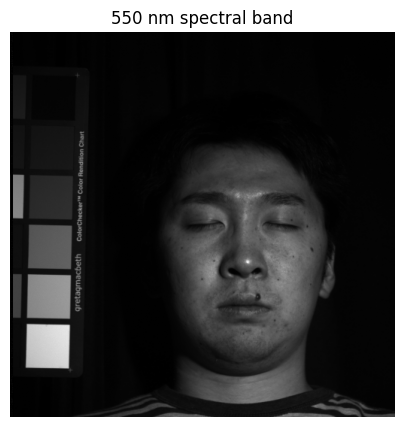

In [ ]:

from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Correct dataset location
folder = Path(
    "/content/drive/MyDrive/HSI_Data/ALL_HSI_DATA/face_ms/face_ms"
)

wavelengths = np.arange(400, 701, 10)

bands = []

for i in range(1, 32):
    filename = folder / f"face_ms_{i}.png"

    band = cv2.imread(str(filename), cv2.IMREAD_UNCHANGED)

    if band is None:
        raise FileNotFoundError(filename)

    bands.append(band.astype(np.float64))

cube = np.stack(bands, axis=-1)

print("Cube shape:", cube.shape)
print("Data type:", cube.dtype)
print("Minimum:", cube.min())
print("Maximum:", cube.max())

plt.figure(figsize=(6, 5))
plt.imshow(cube[:, :, 15], cmap="gray")
plt.title("550 nm spectral band")
plt.axis("off")
plt.show()


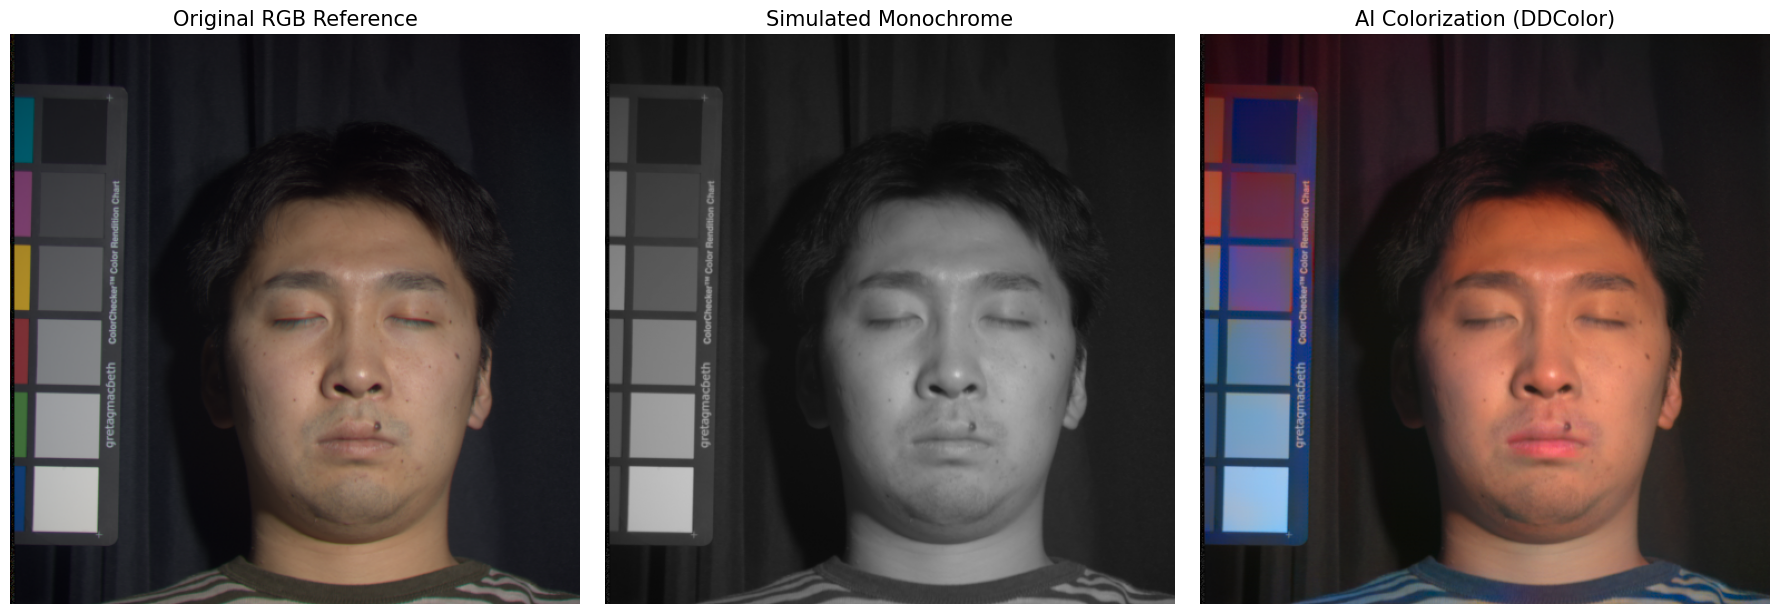

In [ ]:

import numpy as np
import cv2
import matplotlib.pyplot as plt

# ==========================================
# 1. Simulate monochrome camera response
# ==========================================

# Uniform spectral sensitivity (initial baseline)
sensitivity = np.ones(31, dtype=np.float64)
weights = sensitivity / sensitivity.sum()

mono = np.tensordot(cube, weights, axes=([2], [0]))

# Assume 16-bit reflectance encoding
mono_linear = np.clip(mono / 65535.0, 0, 1)

# Linear-to-sRGB display conversion
mono_display = np.where(
    mono_linear <= 0.0031308,
    12.92 * mono_linear,
    1.055 * mono_linear ** (1 / 2.4) - 0.055
)

mono_uint8 = np.round(
    np.clip(mono_display, 0, 1) * 255
).astype(np.uint8)

# ==========================================
# 2. AI colorization using DDColor
# ==========================================

mono_bgr = cv2.cvtColor(
    mono_uint8,
    cv2.COLOR_GRAY2BGR
)

colorized_bgr = colorizer.process(mono_bgr)

colorized_rgb = cv2.cvtColor(
    colorized_bgr,
    cv2.COLOR_BGR2RGB
)

# ==========================================
# 3. Load original RGB reference
# ==========================================

reference_path = folder / "face_RGB.bmp"

reference_bgr = cv2.imread(str(reference_path))

if reference_bgr is None:
    raise FileNotFoundError(reference_path)

reference_rgb = cv2.cvtColor(
    reference_bgr,
    cv2.COLOR_BGR2RGB
)

# Check alignment
if reference_rgb.shape[:2] != mono_uint8.shape:
    print("Warning: RGB reference dimensions differ.")
    print("Reference:", reference_rgb.shape)
    print("Monochrome:", mono_uint8.shape)

# ==========================================
# 4. Display all three images
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(reference_rgb)
axes[0].set_title("Original RGB Reference", fontsize=15)

axes[1].imshow(
    mono_uint8,
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[1].set_title("Simulated Monochrome", fontsize=15)

axes[2].imshow(colorized_rgb)
axes[2].set_title("AI Colorization (DDColor)", fontsize=15)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()



Processing: flowers_ms
Cube: (512, 512, 31)
DDColor completed.
RGB reference found: True

Processing: fake_and_real_strawberries_ms
Cube: (512, 512, 31)
DDColor completed.
RGB reference found: True

Processing: balloons_ms
Cube: (512, 512, 31)
DDColor completed.
RGB reference found: True

Processing: paints_ms
Cube: (512, 512, 31)
DDColor completed.
RGB reference found: True

Processing: chart_and_stuffed_toy_ms
Cube: (512, 512, 31)
DDColor completed.
RGB reference found: True


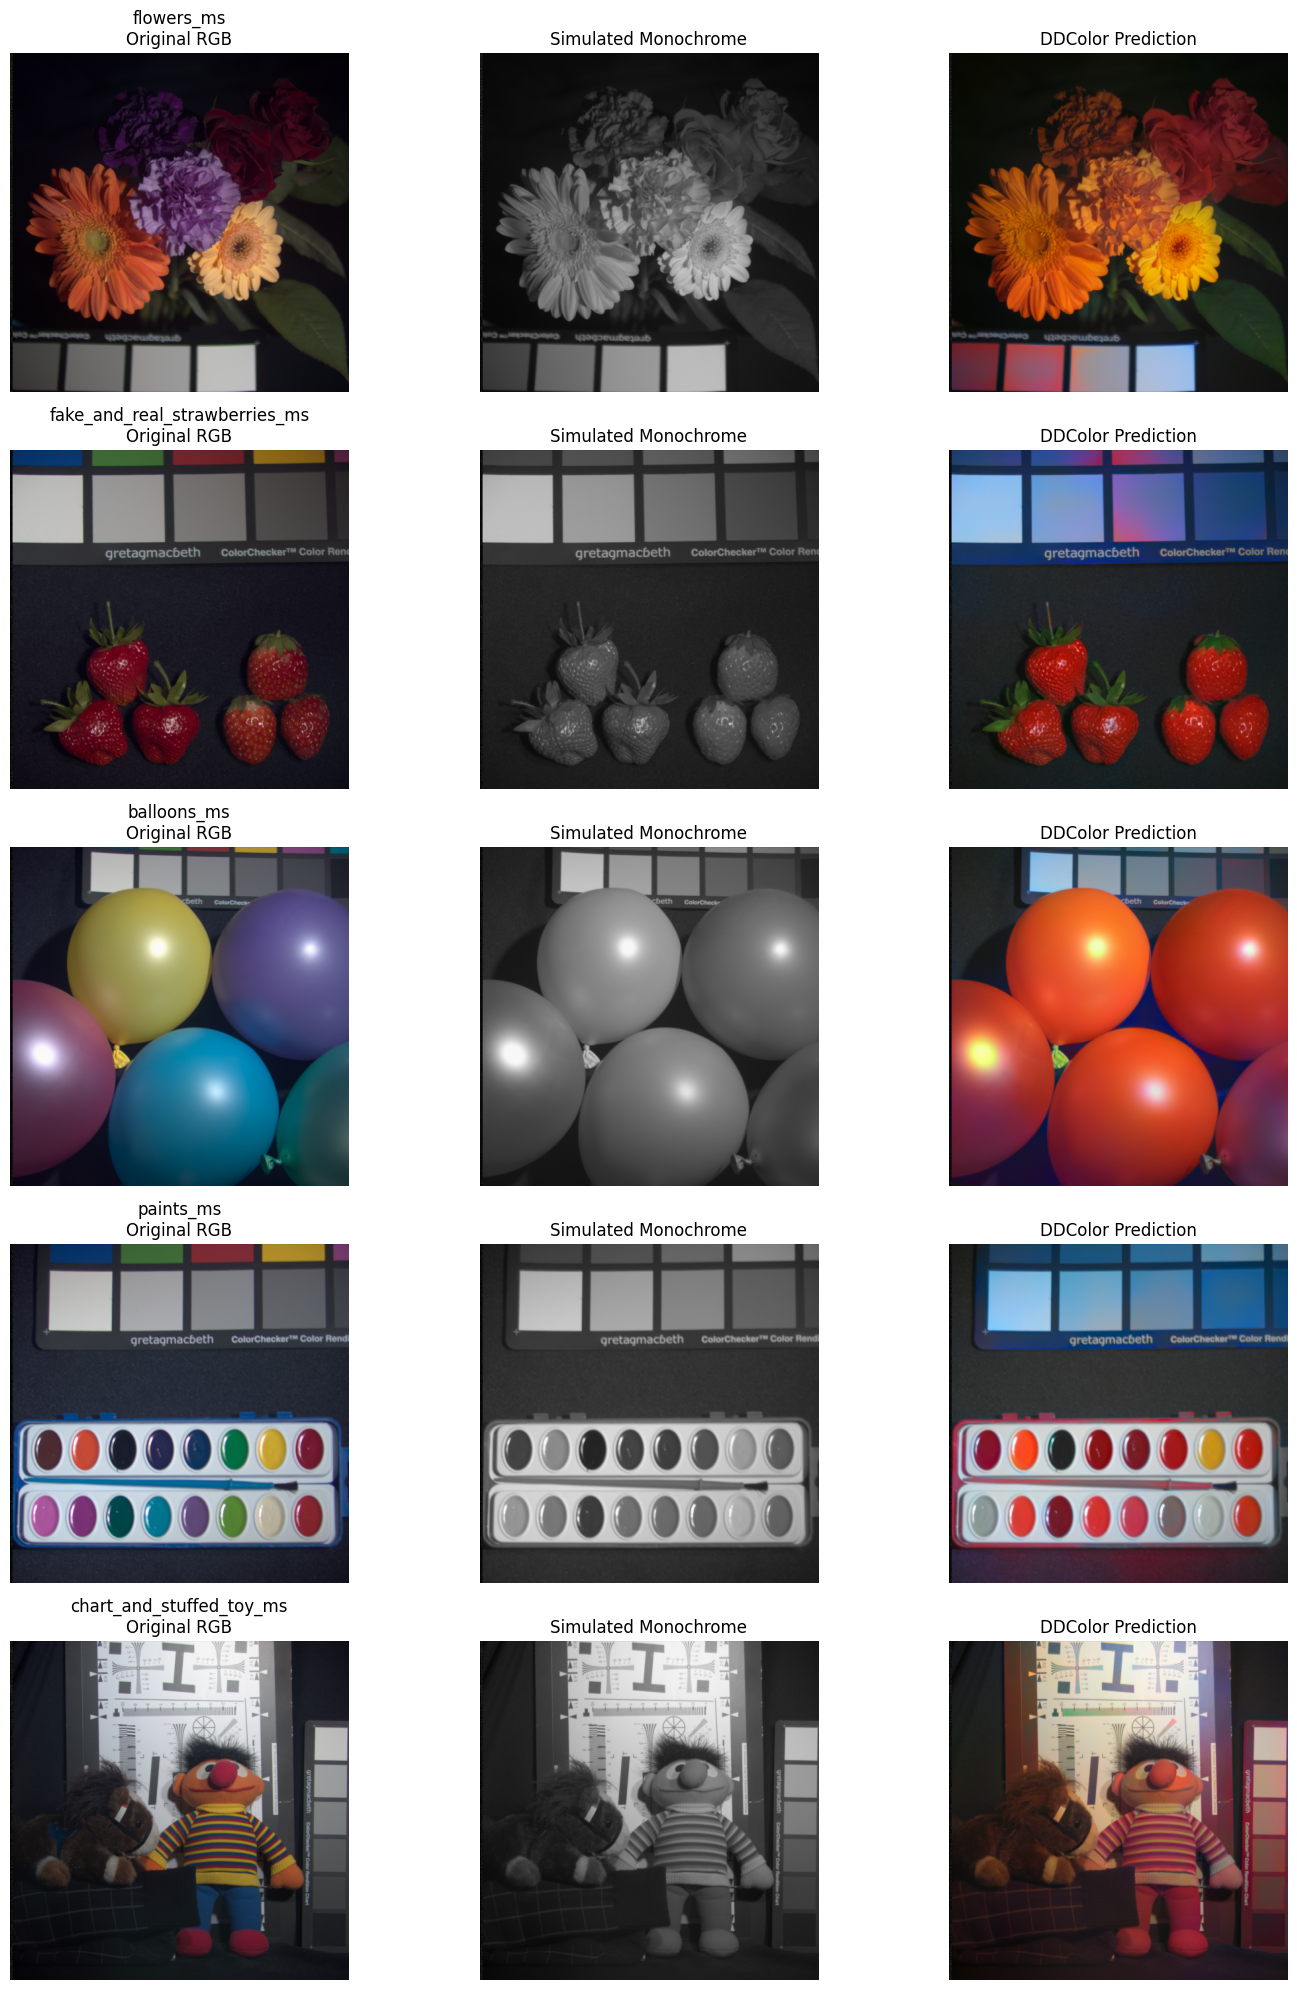

In [ ]:

from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt

# ==========================================
# Five-scene DDColor experiment
# Independent of previous load_scene()
# ==========================================

root = Path(
    "/content/drive/MyDrive/HSI_Data/ALL_HSI_DATA"
)

scenes = [
    "flowers_ms",
    "fake_and_real_strawberries_ms",
    "balloons_ms",
    "paints_ms",
    "chart_and_stuffed_toy_ms"
]

results_new = {}

for scene in scenes:
    print(f"\nProcessing: {scene}")

    # Account for nested scene folders
    folder = root / scene / scene

    if not folder.is_dir():
        folder = root / scene

    if not folder.is_dir():
        print("Folder not found. Skipping.")
        continue

    # Load EXACTLY 31 numbered bands
    bands = []

    for i in range(1, 32):
        path = folder / f"{scene}_{i}.png"

        if not path.is_file():
            raise FileNotFoundError(path)

        band = cv2.imread(
            str(path), cv2.IMREAD_UNCHANGED
        )

        if band is None or band.ndim != 2:
            raise ValueError(f"Invalid band: {path}")

        bands.append(band.astype(np.float64))

    cube_scene = np.stack(bands, axis=-1)

    print("Cube:", cube_scene.shape)

    # ======================================
    # Simulated monochrome sensor
    # ======================================

    # Uniform sensitivity, same as before
    mono = cube_scene.mean(axis=2)

    # Common 16-bit reflectance scaling
    mono_linear = np.clip(
        mono / 65535.0, 0, 1
    )

    # Linear-to-sRGB display conversion
    mono_display = np.where(
        mono_linear <= 0.0031308,
        12.92 * mono_linear,
        1.055 * mono_linear ** (1 / 2.4) - 0.055
    )

    mono_uint8 = np.round(
        np.clip(mono_display, 0, 1) * 255
    ).astype(np.uint8)

    # ======================================
    # Pretrained DDColor inference
    # ======================================

    mono_bgr = cv2.cvtColor(
        mono_uint8, cv2.COLOR_GRAY2BGR
    )

    prediction_bgr = colorizer.process(mono_bgr)

    prediction_rgb = cv2.cvtColor(
        prediction_bgr, cv2.COLOR_BGR2RGB
    )

    # ======================================
    # Original RGB reference (comparison only)
    # ======================================

    reference_rgb = None

    reference_files = [
        folder / f"{scene.replace('_ms', '')}_RGB.bmp",
        folder / f"{scene}_RGB.bmp",
    ]

    reference_files += list(folder.glob("*RGB*.bmp"))
    reference_files += list(folder.glob("*rgb*.bmp"))

    for ref_path in reference_files:
        if ref_path.is_file():
            ref_bgr = cv2.imread(str(ref_path))
            if ref_bgr is not None:
                reference_rgb = cv2.cvtColor(
                    ref_bgr, cv2.COLOR_BGR2RGB
                )
                break

    results_new[scene] = {
        "reference": reference_rgb,
        "mono": mono_uint8,
        "prediction": prediction_rgb
    }

    print("DDColor completed.")
    print("RGB reference found:", reference_rgb is not None)


# ==========================================
# Display all results
# ==========================================

if not results_new:
    raise RuntimeError("No scenes were processed.")

fig, axes = plt.subplots(
    len(results_new), 3,
    figsize=(15, 4 * len(results_new)),
    squeeze=False
)

for row, (scene, data) in enumerate(results_new.items()):

    ref = data["reference"]

    if ref is not None:
        axes[row, 0].imshow(ref)
    else:
        axes[row, 0].text(
            0.5, 0.5, "Reference not found",
            ha="center", va="center",
            transform=axes[row, 0].transAxes
        )

    axes[row, 1].imshow(
        data["mono"],
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[row, 2].imshow(data["prediction"])

    axes[row, 0].set_title(f"{scene}\nOriginal RGB")
    axes[row, 1].set_title("Simulated Monochrome")
    axes[row, 2].set_title("DDColor Prediction")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()
